# Eje 5b — Binomial: americanas y convergencia

Derivados Financieros — QUANt UCEMA

En cada nodo de una **americana** comparamos el valor de **seguir** (hold) con el de **ejercer**.
Cuando $N$ crece, el precio europeo CRR se acerca a **Black–Scholes**.

| Notebook | Contenido |
|----------|-----------|
| **05a** | CRR europea paso a paso |
| **05b** (este) | Americanas + convergencia a BS |
| **06** | Black–Scholes propiamente dicho |

## 1) Setup

In [1]:
import math
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
for p in [ROOT, *ROOT.parents]:
    if (p / "Codigo" / "pricing").exists():
        sys.path.insert(0, str(p))
        break

from Codigo.pricing import (
    opcion_europea_bin,
    opcion_americana_bin,
    opcion_europea_bs,
)
from Codigo.utils.binomial_tree import plot_crr_tree
print("OK")

OK


## 2) Regla de ejercicio temprano

En el nodo $(i,t)$:

$$
V = e^{-r\Delta t}\max\big(\underbrace{q V_u+(1-q)V_d}_{\text{hold}},\; \underbrace{\text{payoff}(S_{i,t})}_{\text{ejercer}}\big)
$$

(en la implementación del repo el $\max$ se toma **dentro** del descuento de forma equivalente).

Intuición:
- **Call** sin dividendos: casi nunca conviene ejercer temprano → americana ≈ europea.
- **Put** (o call con dividendos altos): el ejercicio temprano puede valer.

In [2]:
S, K, T, r, sigma = 100.0, 100.0, 1.0, 0.05, 0.25
pasos = 200

def tabla(div):
    rows = []
    for tipo in ("C", "P"):
        eur = opcion_europea_bin(tipo, S, K, T, r, sigma, div, pasos)
        ame = opcion_americana_bin(tipo, S, K, T, r, sigma, div, pasos)
        rows.append({"div": div, "tipo": tipo, "europea": eur, "americana": ame, "premio_early": ame - eur})
    return rows

import pandas as pd
df = pd.DataFrame(tabla(0.0) + tabla(0.04))
display(df.round(6))
print("Con div=0 el call americana ≈ europea; el put americana > europea.")

,div,tipo,europea,americana,premio_early
0,0.00,C,12.323646,12.323646,0.000000
1,0.00,P,7.446589,7.967099,0.520510
2,0.04,C,9.983721,10.011943,0.028221
3,0.04,P,9.027720,9.206038,0.178318


Con div=0 el call americana ≈ europea; el put americana > europea.


## 3) Mini-árbol americana (N=3) — put

Repetimos la lógica de 05a pero con $\max(\text{hold}, K-S)$ en cada nodo.

In [3]:
tipo = "P"
pasos = 3
div = 0.0
dt = T / pasos
fwd = math.exp((r - div) * dt)
desc = math.exp(-r * dt)
u = math.exp(sigma * math.sqrt(dt))
d = 1 / u
q = (fwd - d) / (u - d)

ST = np.array([S * (u ** (pasos - 2 * i)) for i in range(pasos + 1)])
V = np.zeros((pasos + 1, pasos + 1))
for i in range(pasos + 1):
    V[i, pasos] = max(K - ST[i], 0.0)

for j in range(1, pasos + 1):
    col = pasos - j
    for i in range(pasos + 1 - j):
        hold = q * V[i, col + 1] + (1 - q) * V[i + 1, col + 1]
        # spot en el nodo: mismo exponente que en Codigo.pricing.american_binomial
        spot_nodo = S * (u ** (-2 * i + pasos - j))
        exercise = max(K - spot_nodo, 0.0)
        V[i, col] = desc * max(hold, exercise)

print("Árbol put americana N=3:")
print(np.round(V, 4))
print(f"Precio manual = {V[0,0]:.6f}")
print(f"opcion_americana_bin = {opcion_americana_bin('P', S, K, T, r, sigma, div, pasos):.6f}")

Árbol put americana N=3:
[[ 8.4995  2.9703  0.      0.    ]
 [ 0.     14.8364  6.3184  0.    ]
 [ 0.      0.     24.66   13.4404]
 [ 0.      0.      0.     35.1448]]
Precio manual = 8.499524
opcion_americana_bin = 8.499524


## 3b) Árbol americana dibujado

Compará visualmente un put europeo vs americano (N=4).

En la americana, los nodos en **rojo** son donde `max(hold, intrinsic) = intrinsic`:
conviene **ejercer temprano**. Esa región no existe en la europea (solo se ejerce
al vencimiento) y es exactamente el premio por early exercise.

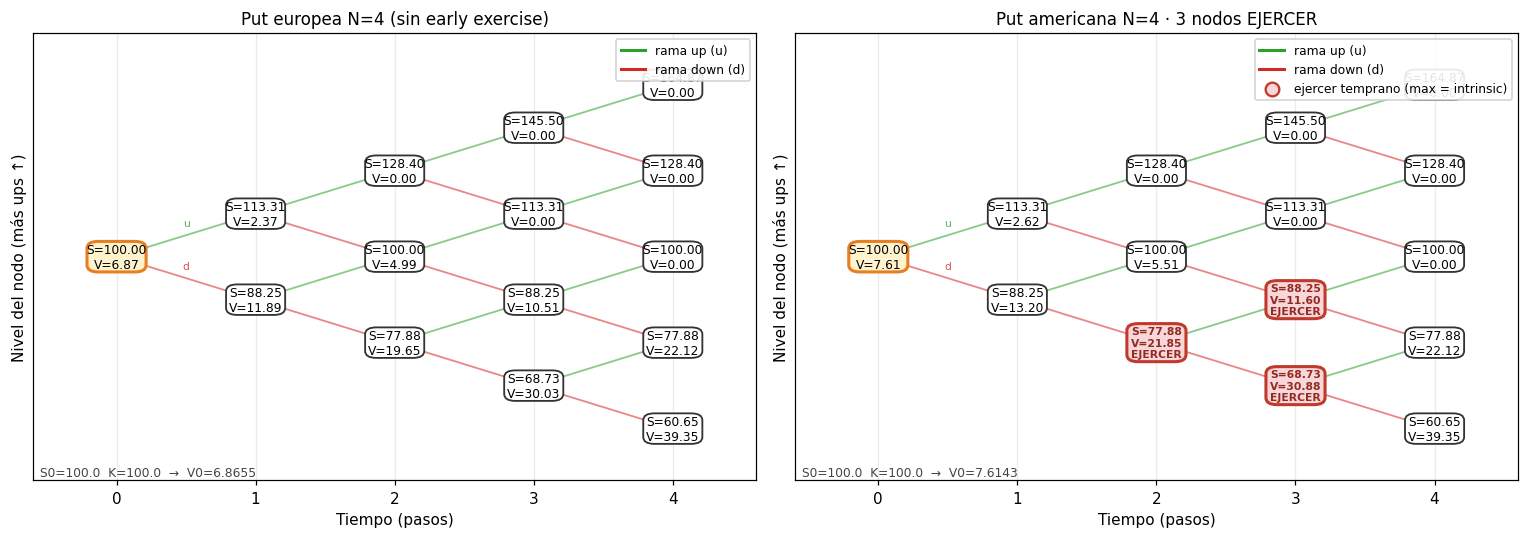

Nodos donde max = intrinsic (ejercer): 3


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=110)
plot_crr_tree("P", S, K, T, r, sigma, 0.0, 4, americana=False, show="both", ax=axes[0],
              title="Put europea N=4 (sin early exercise)")
from Codigo.utils.binomial_tree import build_crr_lattices
_, _, meta_ame = build_crr_lattices("P", S, K, T, r, sigma, 0.0, 4, americana=True)
plot_crr_tree("P", S, K, T, r, sigma, 0.0, 4, americana=True, show="both", ax=axes[1],
              title=f"Put americana N=4 · {meta_ame['n_ejercer']} nodos EJERCER")
plt.tight_layout()
plt.show()
print(f"Nodos donde max = intrinsic (ejercer): {meta_ame['n_ejercer']}")

## 4) Convergencia del binomial europeo a Black–Scholes

Fijamos parámetros y barremos $N$. El error $|V_{bin}-V_{BS}|$ debería bajar (con oscilación típica de CRR).

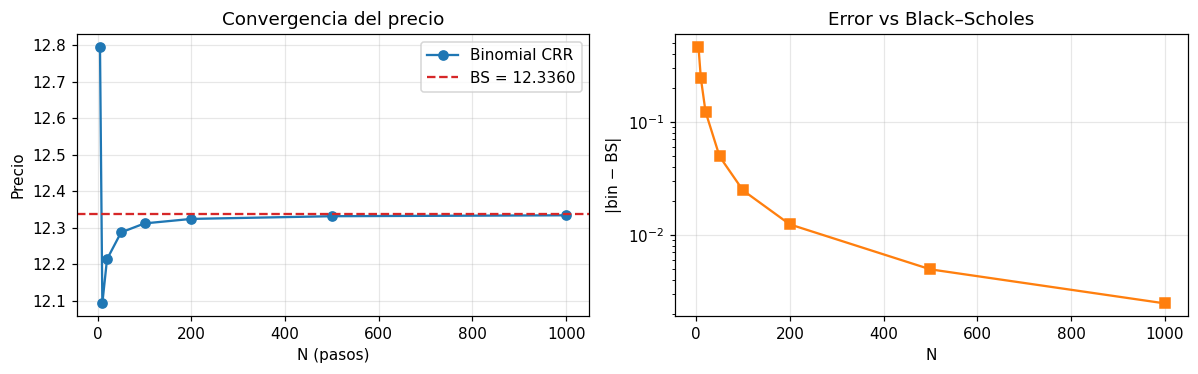

   N  binomial    error
   5 12.794645 0.458646
  10 12.092254 0.243745
  20 12.213216 0.122783
  50 12.286685 0.049314
 100 12.311310 0.024689
 200 12.323646 0.012352
 500 12.331056 0.004943
1000 12.333527 0.002472


In [5]:
tipo = "C"
div = 0.0
bs = opcion_europea_bs(tipo, S, K, T, r, sigma, div)
Ns = [5, 10, 20, 50, 100, 200, 500, 1000]
vals = [opcion_europea_bin(tipo, S, K, T, r, sigma, div, n) for n in Ns]
err = [abs(v - bs) for v in vals]

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5), dpi=110)
ax[0].plot(Ns, vals, "o-", label="Binomial CRR")
ax[0].axhline(bs, color="C3", ls="--", label=f"BS = {bs:.4f}")
ax[0].set_xlabel("N (pasos)"); ax[0].set_ylabel("Precio")
ax[0].set_title("Convergencia del precio"); ax[0].legend(); ax[0].grid(True, alpha=0.3)

ax[1].semilogy(Ns, err, "s-", color="C1")
ax[1].set_xlabel("N"); ax[1].set_ylabel("|bin − BS|")
ax[1].set_title("Error vs Black–Scholes"); ax[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(pd.DataFrame({"N": Ns, "binomial": vals, "error": err}).round(6).to_string(index=False))

## Resumen

- Americana = en cada nodo, $\max(\text{continuación}, \text{ejercicio})$.
- Sin dividendos, call americana ≈ europea; puts (y calls con div) pueden tener premio por early exercise.
- CRR europeo $\to$ Black–Scholes cuando $N\to\infty$.
- **Ejercicio:** con `div=0.05`, ¿para qué strikes un call ATM de 1Y muestra premio americano visible?
- **Siguiente:** **06a** — fórmula de Black–Scholes.